# Telecom Customer Churn Prediction
GCI World April 2026, Final Assignment | Kieran McKend

This notebook is the evidence base for a churn-retention proposal to Telecom, an anonymised telecommunications provider with 100,000 customers. It predicts which customers will cancel 31-60 days after an observation date, explains *why*, and turns the predictions into a costed campaign.

### Summary of results

| | |
|---|---|
| Final model | LightGBM, Optuna-tuned, 5-seed average (102 features) |
| Test AUC-ROC | 0.703 (95% CI 0.696-0.709) vs 0.642 for Logistic Regression |
| Riskiest 10% who really churn | 81.5% in the balanced sample, ~9% at a realistic 3% monthly churn rate (3x average) |
| Top drivers | handset age, tenure (spike at ~12 months), usage falling relative to the customer's own history |
| Business case | A fixed top-10% campaign loses ~\$0.2M per 100k customers at real churn rates. Contacting only customers with positive expected value earns +\$23k, or +\$270k if the offer costs a quarter of a month's revenue |
| Next step | Randomised pilot, ~490 customers per arm, to measure retention success and offer cost |

### Contents
1. [Setup](#1.-Setup) | 2. [Exploratory data analysis](#2.-Exploratory-Data-Analysis) | 3. [Problem definition](#3.-Problem-Definition) | 4. [Data preparation](#4.-Data-Preparation) | 5. [Models](#5.-Model-Development) | 6. [Tuning](#6.-Hyperparameter-Tuning) | 7. [Test evaluation](#7.-Final-Evaluation-on-the-Held-Out-Test-Set) | 8. [SHAP](#8.-SHAP-Interpretation) | 9. [Business impact](#9.-Business-Impact) | 10. [Conclusion](#10.-Conclusion) | [References](#References)

> Reproducibility. Reusable code lives in the [`churn/`](churn/) package, and this notebook holds the analysis and narrative. One seed (`SEED = 42`) is passed to every random operation, so *Restart & Run All* reproduces every number here and in the slides in about 7 minutes. The optional hyperparameter search (Section 6) adds about 45 minutes.

---
## 1. Setup

The notebook reads `Client.csv` and `Record.csv` from a folder named `telecom/` next to this notebook; change `DATA_DIR` in `churn/config.py` to use another location. *On Google Colab:* mount Drive and point `DATA_DIR` at the folder holding the CSVs.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    brier_score_loss,
    classification_report,
    confusion_matrix,
)
from sklearn.model_selection import StratifiedKFold

from churn import business, models, plotting
from churn import evaluation as ev
from churn.config import CHURN_C, FINAL_LR, GREEN_C, SEED, SEEDS, STAY_C, TUNED_PARAMS, Assumptions
from churn.data import ENGINEERED, load_data, make_xy, split_60_20_20
from churn.preprocessing import TreePreprocessor, column_types, make_logreg

np.random.seed(SEED)
plotting.set_style()

df = load_data()
print(f"Merged : {df.shape}")
df.head()

Client : (100000, 50)   Record : (100000, 51)
Merged : (100000, 100)


,rev_Mean,mou_Mean,totmrc_Mean,da_Mean,ovrmou_Mean,ovrrev_Mean,vceovr_Mean,datovr_Mean,roam_Mean,change_mou,...,dwllsize,forgntvl,ethnic,kid0_2,kid3_5,kid6_10,kid11_15,kid16_17,creditcd,eqpdays
0,23.9975,219.25,22.500,0.2475,0.00,0.0,0.0,0.0,0.0,-157.25,...,A,0.0,N,U,U,U,U,U,Y,361.0
1,57.4925,482.75,37.425,0.2475,22.75,9.1,9.1,0.0,0.0,532.25,...,A,0.0,Z,U,U,U,U,U,Y,240.0
2,16.9900,10.25,16.990,0.0000,0.00,0.0,0.0,0.0,0.0,-4.25,...,A,0.0,N,U,Y,U,U,U,Y,1504.0
3,38.0000,7.50,38.000,0.0000,0.00,0.0,0.0,0.0,0.0,-1.50,...,D,0.0,U,Y,U,U,U,U,Y,1812.0
4,55.2300,570.50,71.980,0.0000,0.00,0.0,0.0,0.0,0.0,38.50,...,O,0.0,I,U,U,U,U,U,Y,434.0


| File | Contents |
|---|---|
| `Client.csv` | Account-level information: plan, handset, credit class, household demographics |
| `Record.csv` | Mean monthly usage and billing, call-quality indicators, tenure, and the `churn` target |

The inner join on `Customer_ID` keeps all 100,000 customers, so nothing is lost in the merge.

---
## 2. Exploratory Data Analysis

The EDA answers three design questions: how to encode and impute the data, which metric suits the target, and which customer characteristics are linked to churn and could become campaign levers.

### 2.1 Data types and missing values

In [2]:
df.info(verbose=False)

missing = df.isna().mean().sort_values(ascending=False)
print("\nTop 10 columns by missing rate:")
print(missing.head(10).round(3).to_string())
print(f"\nColumns > 60% missing: {(missing > 0.60).sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Columns: 100 entries, rev_Mean to eqpdays
dtypes: float64(69), int64(10), str(21)
memory usage: 76.3 MB

Top 10 columns by missing rate:
numbcars      0.494
dwllsize      0.383
HHstatin      0.379
ownrent       0.337
dwlltype      0.319
lor           0.302
income        0.254
adults        0.230
infobase      0.221
hnd_webcap    0.102

Columns > 60% missing: 0


No column exceeds 60% missing. The worst is `numbcars` at about 49%, and most gaps are in the optional household-demographics block. No column is dropped for missingness. Numeric gaps are imputed with the training-set median, and categorical gaps are kept as their own "missing" level (Section 4.2).

### 2.2 Target: churn

`churn` = 1 if the customer left 31-60 days after the observation date (data dictionary).

Churned: 49,562 (49.6%)   Stayed: 50,438 (50.4%)


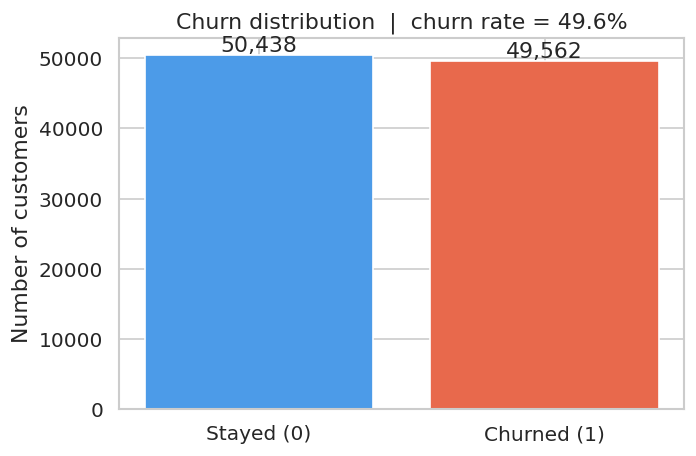

In [3]:
churn_rate = df["churn"].mean()
counts = df["churn"].value_counts().sort_index()
print(f"Churned: {counts[1]:,} ({churn_rate:.1%})   Stayed: {counts[0]:,} ({1 - churn_rate:.1%})")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Stayed (0)", "Churned (1)"], counts.values, color=[STAY_C, CHURN_C], edgecolor="white")
for i, v in enumerate(counts.values):
    ax.text(i, v + 500, f"{v:,}", ha="center")
ax.set_ylabel("Number of customers")
ax.set_title(f"Churn distribution  |  churn rate = {churn_rate:.1%}")
plt.tight_layout()
plt.show()

The classes are almost perfectly balanced. A 50% churn rate in one month is far above anything a real operator experiences: annual industry churn is usually quoted at 20-40% (Nguyen et al., 2022). The dataset is therefore almost certainly a balanced sample. Its column names appear to match the Teradata Center / Duke University churn-tournament data (Neslin et al., 2006). This has two consequences:

- **Metric.** AUC-ROC is the primary metric because the campaign *ranks* customers by risk, and ranking quality does not depend on the base rate.
- **Business sizing.** Precision measured on this sample overstates precision on the real customer base. Section 9.2 corrects for this.

### 2.3 Handset age

churn
stayed     363.0
churned    421.0 

              rate  customers
eqpdays                      
<3 months    39.9%       9655
3-6 months   43.8%       8672
6-12 months  47.0%      36356
1-2 years    53.8%      34505
2+ years     57.9%      10811


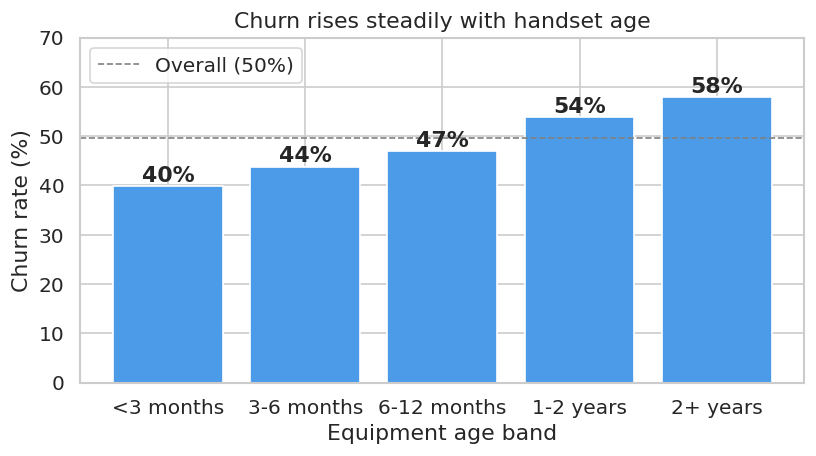

In [4]:
print(df.groupby("churn")["eqpdays"].mean().rename({0: "stayed", 1: "churned"}).round(0).to_string(), "\n")

eqp = ev.churn_rate_by(
    df,
    "eqpdays",
    bins=[-np.inf, 90, 180, 365, 730, np.inf],
    labels=["<3 months", "3-6 months", "6-12 months", "1-2 years", "2+ years"],
)
print(eqp.assign(rate=eqp["rate"].map("{:.1%}".format)).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
plotting.rate_bars(
    ax, eqp["rate"], churn_rate, title="Churn rises steadily with handset age", xlabel="Equipment age band"
)
ax.legend(loc="upper left")
plt.tight_layout()
plotting.save_fig(fig, "eda_equipment_age")
plt.show()

Churners' handsets are about two months older on average (421 vs 363 days). Churn rises monotonically, from 40% for handsets under 3 months old to 58% for handsets over 2 years old. This makes handset age both a strong feature and the clearest lever for an upgrade offer.

### 2.4 Tenure: the contract-renewal window

         rate  customers
months                  
6-10    33.8%      18381
11-12   63.7%      14062
13-15   53.8%      14038
16-24   50.8%      28830
25+     49.4%      24689


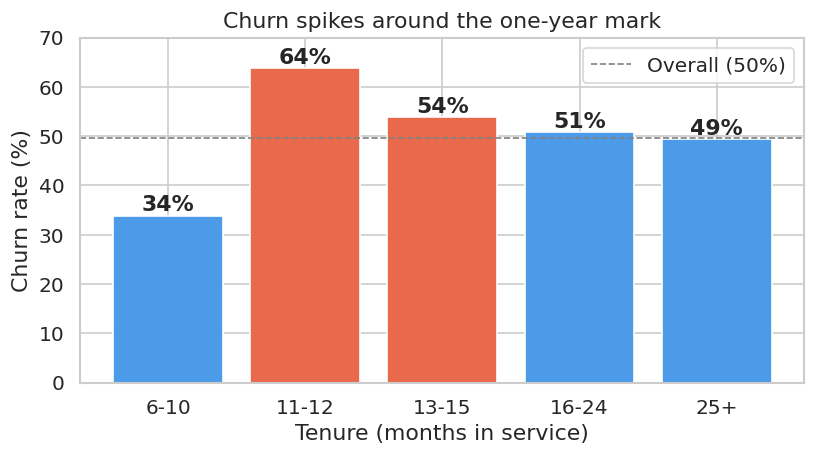

In [5]:
ten = ev.churn_rate_by(
    df, "months", bins=[0, 10, 12, 15, 24, np.inf], labels=["6-10", "11-12", "13-15", "16-24", "25+"]
)
print(ten.assign(rate=ten["rate"].map("{:.1%}".format)).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
colors = [CHURN_C if b in ("11-12", "13-15") else STAY_C for b in ten.index]
plotting.rate_bars(
    ax,
    ten["rate"],
    churn_rate,
    colors=colors,
    title="Churn spikes around the one-year mark",
    xlabel="Tenure (months in service)",
)
ax.legend(loc="upper right")
plt.tight_layout()
plotting.save_fig(fig, "eda_tenure")
plt.show()

Churn is not highest among the newest customers. It is lowest in the first ten months (34%), nearly doubles to 64% at 11-12 months, and stays elevated through month 15. That pattern fits customers coming off a 12-month contract and becoming free to leave without penalty. Contract terms are not in the data, so this is an inference, but it gives a clear trigger: contact customers *before* their one-year anniversary.

### 2.5 Customer-care calls and usage trend

                rate  customers
custcare_Mean                  
0              0.518      55692
0-1            0.494      16100
1-3            0.462      12186
3+             0.447      16022 

Correlation custcare_Mean vs churn: -0.036

                 rate  customers
change_mou                      
Fell > 100 min  0.536      22585
Fell 0-100 min  0.494      31066
Flat or rose    0.471      45458


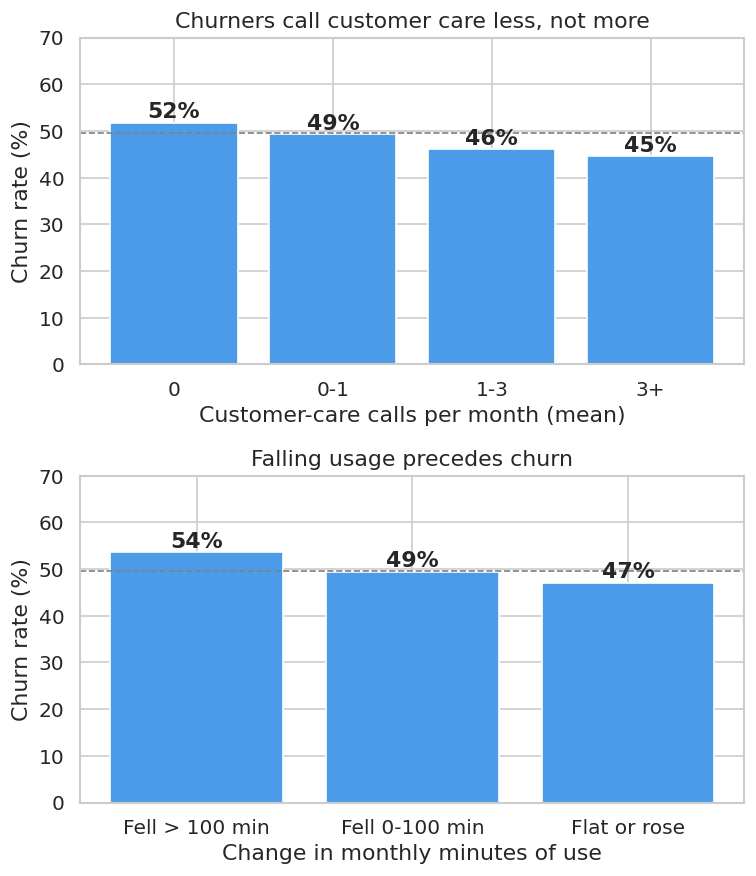

In [6]:
care = ev.churn_rate_by(
    df, "custcare_Mean", bins=[-np.inf, 0, 1, 3, np.inf], labels=["0", "0-1", "1-3", "3+"]
)
usage = ev.churn_rate_by(
    df,
    "change_mou",
    bins=[-np.inf, -100, 0, np.inf],
    labels=["Fell > 100 min", "Fell 0-100 min", "Flat or rose"],
    right=False,
)
print(care.round(3).to_string(), "\n")
print(f"Correlation custcare_Mean vs churn: {df['custcare_Mean'].corr(df['churn']):+.3f}\n")
print(usage.round(3).to_string())

fig, axes = plt.subplots(2, 1, figsize=(6.5, 7.5), sharey=True)
plotting.rate_bars(
    axes[0],
    care["rate"],
    churn_rate,
    overall_label=False,
    title="Churners call customer care less, not more",
    xlabel="Customer-care calls per month (mean)",
)
plotting.rate_bars(
    axes[1],
    usage["rate"],
    churn_rate,
    overall_label=False,
    title="Falling usage precedes churn",
    xlabel="Change in monthly minutes of use",
)
plt.tight_layout()
plotting.save_fig(fig, "eda_care_usage")
plt.show()

**Disengaged customers leave quietly.**

- Customers who never call customer care churn *more* (52%) than frequent callers (45%). Churners do not visibly complain before leaving, so a complaint-driven retention process would miss most of them.
- Customers whose monthly minutes fell by more than 100 churn at 54%, against 47% for customers with flat or rising usage.

Both effects are real but modest, and no single variable separates the classes. That is why a model combining many weak signals is needed rather than a business rule.

### 2.6 Credit class

54 credit classes; 11 have >= 500 customers (95.3% of the base)


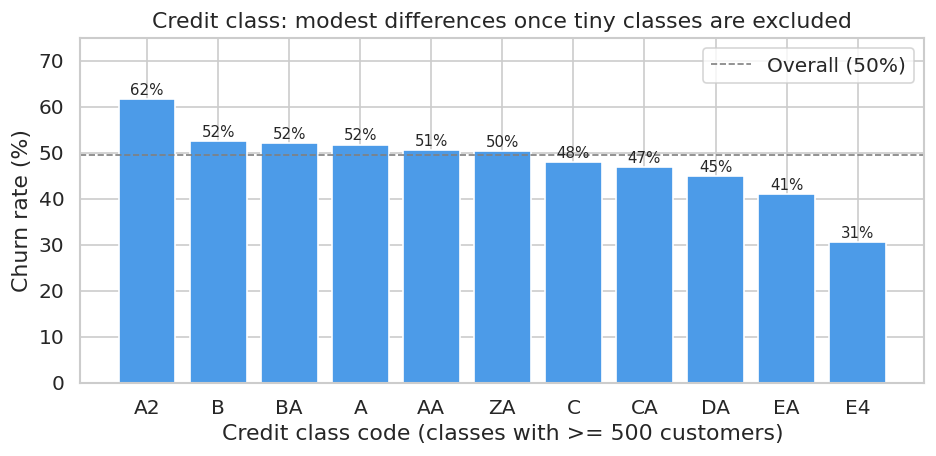

In [7]:
MIN_CUSTOMERS = 500  # tiny classes (some < 10 customers) produce meaningless 0% / 100% rates
credit = ev.churn_rate_by(df, "crclscod")
big = credit[credit["customers"] >= MIN_CUSTOMERS].sort_values("rate", ascending=False)
print(
    f"{len(credit)} credit classes; {len(big)} have >= {MIN_CUSTOMERS} customers "
    f"({big['customers'].sum() / len(df):.1%} of the base)"
)

fig, ax = plt.subplots(figsize=(8, 4))
plotting.rate_bars(
    ax,
    big["rate"],
    churn_rate,
    ylim=75,
    bold=False,
    fontsize=9,
    title="Credit class: modest differences once tiny classes are excluded",
    xlabel=f"Credit class code (classes with >= {MIN_CUSTOMERS} customers)",
)
ax.legend()
plt.tight_layout()
plotting.save_fig(fig, "eda_credit_class")
plt.show()

Only 11 of the 54 credit classes have at least 500 customers, and together they cover 95% of the base. The extreme 80-100% rates seen when every class is plotted come from classes with a handful of customers. Among the well-populated classes, churn ranges from 31% to 62%, and the E and D classes churn *less* than A and B. The codes are undefined in the data dictionary, so we do not read them as "good" or "bad" credit. Credit class stays in the model as a feature but is not used as a campaign trigger.

### 2.7 Correlation screen for leakage

In [8]:
corr = df.select_dtypes(include=np.number).corr()["churn"].drop("churn").abs().sort_values(ascending=False)
print(corr.head(10).round(4).to_string())

eqpdays          0.1127
hnd_price        0.1032
totmrc_Mean      0.0686
mou_Mean         0.0570
mou_cvce_Mean    0.0520
complete_Mean    0.0517
comp_vce_Mean    0.0516
avg3mou          0.0495
mou_opkv_Mean    0.0489
attempt_Mean     0.0485


No feature correlates suspiciously strongly with the target, so there is no sign of leakage. The strongest linear correlation is only 0.11 (`eqpdays`): the signal is spread thinly across many features. The revenue and usage columns are highly inter-correlated. Tree ensembles cope with that redundancy by choosing the best split at each node, so no manual de-duplication is needed.

---
## 3. Problem Definition

**Business question.** Which customers are most likely to cancel in the next 31-60 days, and which targeted intervention would retain them at a positive expected return?

**Why churn?** Mobile markets are saturated, with 112 subscriptions per 100 people worldwide (ITU, 2024). Growth therefore depends on keeping customers, and acquiring a new customer costs 5-25x more than retaining one (Gallo, 2014).

**ML formulation.** Binary classification on `churn`. The model outputs a churn probability per customer, which ranks the base for the retention campaign.

**Metrics.**

| Role | Metric | Why |
|---|---|---|
| Primary | AUC-ROC | Ranking quality, independent of cut-off and base rate |
| Business | Top-decile precision | Share of real churners among the customers actually contacted |
| Secondary | F1, precision, recall at 0.5 | Performance at a fixed cut-off |

---
## 4. Data Preparation

### 4.1 Column selection and feature engineering

`make_xy` (in `churn/data.py`) drops four columns:

- `Customer_ID`: an identifier with no predictive value.
- `recv_sms_Mean` and `iwylis_vce_Mean`: undefined in the data dictionary.
- `ethnic`: using ethnicity to decide who receives an offer would be discriminatory, and removing it did not reduce AUC.

The other household fields are kept, since removing them lowered AUC in testing.

Tree models split on one column at a time, so they cannot easily discover *ratios* between columns. Seven engineered features make those relationships explicit:

| Feature | Definition | Intuition |
|---|---|---|
| `overage_ratio` | overage minutes / total minutes | regularly exceeding the plan is a friction point |
| `mou_change_pct` | `change_mou` / `avg3mou` | usage change *relative* to the customer's normal level |
| `rev_change_pct` | `change_rev` / `avg3rev` | the same for spend |
| `recent_vs_life_mou` | `avg3mou` / `avgmou` | recent vs lifetime usage (disengagement) |
| `recent_vs_life_rev` | `avg3rev` / `avgrev` | recent vs lifetime spend |
| `eqp_to_tenure` | `eqpdays` / (`months` x 30.4) | about 1 means still on the handset they joined with |
| `drop_rate` | dropped/blocked / attempted calls | network quality, normalised for volume |

Together they add about +0.007 CV AUC. Other candidates were tested and left out because they gave no gain: a renewal-window flag, care calls per minute, target encoding, LightGBM's native categorical handling, and nine further ratios.

In [9]:
X, y = make_xy(df)
num_cols, cat_cols = column_types(X)
print(
    f"Features: {X.shape[1]}  ({len(num_cols)} numeric incl. {len(ENGINEERED)} engineered, "
    f"{len(cat_cols)} categorical)"
)

Features: 102  (82 numeric incl. 7 engineered, 20 categorical)


### 4.2 Split and preprocessing

The data is split 60% train / 20% validation / 20% test, stratified on `churn`. Cross-validation on the training split drives tuning, the validation split compares models, and the test set is used exactly once (Section 7).

`TreePreprocessor` is fitted on training rows only, so no information from held-out rows leaks into it:

- **Numeric:** median imputation.
- **Categorical:** label encoding. Missing values become their own level, and labels unseen in training map to a reserved code. Trees split on thresholds, so the arbitrary integer order does no harm.

For the final model a second preprocessor is fitted on train+validation.

In [10]:
X_train, X_val, X_test, y_train, y_val, y_test = split_60_20_20(X, y)
for name, ys in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(f"{name:<5}: {len(ys):>6,} rows | churn rate {ys.mean():.3f}")

prep = TreePreprocessor(num_cols, cat_cols).fit(X_train)
X_train_t, X_val_t = prep.transform(X_train), prep.transform(X_val)

X_tv, y_tv = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
prep_tv = TreePreprocessor(num_cols, cat_cols).fit(X_tv)
X_tv_t, X_test_t = prep_tv.transform(X_tv), prep_tv.transform(X_test)

Train: 60,000 rows | churn rate 0.496
Val  : 20,000 rows | churn rate 0.496
Test : 20,000 rows | churn rate 0.496


---
## 5. Model Development

Three model families of increasing complexity are compared on the validation split:

| Model | Setup |
|---|---|
| Majority class | Predicts the same class for everyone. AUC = 0.5 by definition; the floor to beat. |
| Logistic Regression | An interpretable linear benchmark with preprocessing that suits a linear model: signed-log transform and standardisation for numerics, one-hot encoding for categoricals (levels under 100 customers grouped), and L2 regularisation (`C=0.1`). |
| LightGBM (defaults) | Gradient-boosted trees (Ke et al., 2017), the standard strong baseline for tabular data with mixed types, heavy tails and correlated columns. Captures non-linear effects (such as the tenure spike) and interactions, and works directly with SHAP. |

In [11]:
results = [
    ev.evaluate(
        "Baseline (majority class)",
        DummyClassifier(strategy="most_frequent"),
        X_train_t,
        y_train,
        X_val_t,
        y_val,
    ),
    ev.evaluate(
        "Logistic Regression", make_logreg(num_cols, cat_cols), X_train, y_train, X_val, y_val
    ),  # raw splits: the pipeline preprocesses itself
    ev.evaluate(
        "LightGBM (defaults)",
        lgb.LGBMClassifier(random_state=SEED, verbose=-1),
        X_train_t,
        y_train,
        X_val_t,
        y_val,
    ),
]
print(ev.results_table(results).to_string(index=False))

                    Model  AUC-ROC  Top-10% prec     F1  Precision  Recall
      LightGBM (defaults)   0.6967        0.8185 0.6398     0.6368  0.6428
      Logistic Regression   0.6416        0.7035 0.5900     0.6026  0.5779
Baseline (majority class)   0.5000        0.4980 0.0000     0.0000  0.0000


---
## 6. Hyperparameter Tuning

**Search.** Optuna (Akiba et al., 2019), using its TPE sampler (Bergstra et al., 2011) for 30 trials, explores `num_leaves`, `min_child_samples`, `colsample_bytree`, `subsample` and `reg_lambda`. Each trial is scored by 5-fold stratified CV on the training split with early stopping, so the number of trees is learned rather than fixed. Row bagging is switched on with `subsample_freq=1`, because LightGBM ignores `subsample` without it.

**Refit.** The search runs at `learning_rate=0.05` for speed. The winner is then refitted at `0.02`, with the number of trees again chosen by CV early stopping.

**Seed averaging.** The final model averages five copies of the tuned model that differ only in random seed. This reduces variance at no accuracy cost.

The search takes about 45 minutes on 2 CPU cores, so by default the notebook uses its stored result from `churn/config.py`. Set `RUN_SEARCH = True` to reproduce it.

In [12]:
RUN_SEARCH = False

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds_train = list(cv.split(X_train_t, y_train))
dtrain = models.make_dataset(X_train_t, y_train)

if RUN_SEARCH:
    study = models.optuna_search(dtrain, folds_train, n_trials=30)
    best = study.best_params
    print(
        study.trials_dataframe().sort_values("value", ascending=False).head(5).round(4).to_string(index=False)
    )
else:
    best = TUNED_PARAMS
print(f"Tuned parameters: {best}")

Tuned parameters: {'num_leaves': 39, 'min_child_samples': 52, 'colsample_bytree': 0.4971, 'subsample': 0.9794, 'reg_lambda': 16.0837}


**Search result** (5-fold CV AUC on the training split at `learning_rate=0.05`, top 5 of 30 trials):

| CV AUC | `num_leaves` | `min_child_samples` | `colsample_bytree` | `subsample` | `reg_lambda` | trees |
|---|---|---|---|---|---|---|
| 0.7006 | 39 | 52 | 0.50 | 0.98 | 16.1 | 239 |
| 0.6999 | 73 | 20 | 0.41 | 0.98 | 19.6 | 224 |
| 0.6996 | 54 | 33 | 0.34 | 0.97 | 21.1 | 251 |
| 0.6996 | 46 | 20 | 0.56 | 0.83 | 25.1 | 252 |
| 0.6993 | 64 | 36 | 0.32 | 0.99 | 28.3 | 212 |

The winners share heavy feature subsampling (30-55% of columns per tree) and strong L2 regularisation; tree size matters much less. That fits a dataset whose signal is spread thinly across many correlated columns. The top five are within 0.0013 AUC of each other, well inside fold-to-fold noise, so the search has converged.

CV AUC at lr 0.02: 0.7012 (871 trees)



                       Model  AUC-ROC  Top-10% prec     F1  Precision  Recall
LightGBM (tuned, 5-seed avg)   0.7043        0.8255 0.6445     0.6417  0.6473
            LightGBM (tuned)   0.7038        0.8215 0.6444     0.6418  0.6471
         LightGBM (defaults)   0.6967        0.8185 0.6398     0.6368  0.6428
         Logistic Regression   0.6416        0.7035 0.5900     0.6026  0.5779
   Baseline (majority class)   0.5000        0.4980 0.0000     0.0000  0.0000


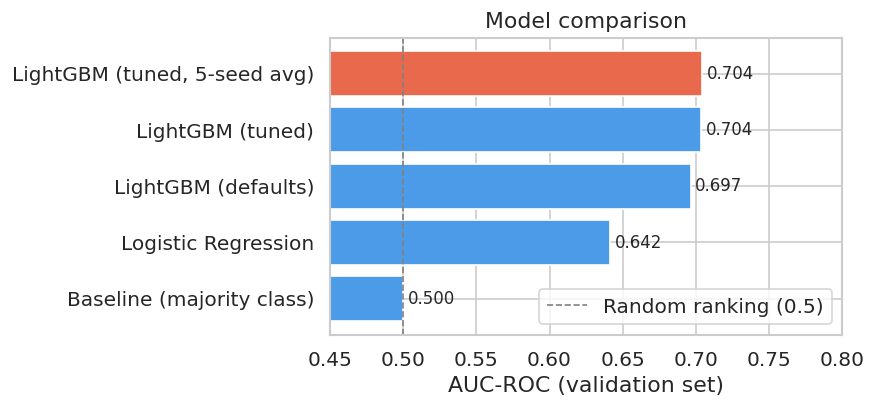

In [13]:
cv_auc, rounds_train = models.cv_auc(best, dtrain, folds_train, lr=FINAL_LR)
print(f"CV AUC at lr {FINAL_LR}: {cv_auc:.4f} ({rounds_train} trees)\n")

results += [
    ev.evaluate(
        "LightGBM (tuned)", models.tuned_lgbm(best, rounds_train), X_train_t, y_train, X_val_t, y_val
    ),
    ev.evaluate(
        "LightGBM (tuned, 5-seed avg)",
        models.SeedEnsemble(best, rounds_train, SEEDS),
        X_train_t,
        y_train,
        X_val_t,
        y_val,
    ),
]
res_df = ev.results_table(results)
print(res_df.to_string(index=False))

fig = plotting.model_comparison(res_df)
plt.tight_layout()
plotting.save_fig(fig, "model_comparison")
plt.show()

- **LightGBM vs Logistic Regression:** +0.06 AUC and +12 points of top-decile precision. Even with preprocessing designed for it, the linear model cannot capture the non-linear effects and interactions.
- **Tuning:** +0.007 AUC over LightGBM's defaults, mostly from the regularisation found by the search plus the lower learning rate.
- **Seed averaging:** +0.0005 AUC and +0.4 points of top-decile precision. A small gain that never hurt, so the 5-seed average becomes the final model.

---
## 7. Final Evaluation on the Held-Out Test Set

The 5-seed model is retrained on train+validation (80% of the data), with the number of trees re-chosen by CV early stopping on those rows. It is then scored once on the untouched test set. A 1,000-sample bootstrap (Efron & Tibshirani, 1993) gives 95% confidence intervals.

In [14]:
dtv = models.make_dataset(X_tv_t, y_tv)
_, rounds_tv = models.cv_auc(best, dtv, list(cv.split(X_tv_t, y_tv)), lr=FINAL_LR)
final_model = models.SeedEnsemble(best, rounds_tv, SEEDS).fit(X_tv_t, y_tv)

y_proba_test = final_model.predict_proba(X_test_t)[:, 1]
y_pred_test = (y_proba_test >= 0.5).astype(int)
yt = y_test.to_numpy()

m = ev.test_metrics(yt, y_proba_test)
ci = ev.bootstrap_ci(yt, y_proba_test)
single_auc = ev.test_metrics(yt, final_model.models_[0].predict_proba(X_test_t)[:, 1])["auc"]

print(f"Final model: {len(SEEDS)} x {rounds_tv} trees at lr {FINAL_LR}\n")
print(
    f"AUC-ROC              {m['auc']:.4f}   95% CI [{ci['auc'][0]:.3f}, {ci['auc'][1]:.3f}]   "
    f"(single seed: {single_auc:.4f})"
)
print(f"Top-decile precision {m['top10']:.4f}   95% CI [{ci['top10'][0]:.3f}, {ci['top10'][1]:.3f}]")
print(
    f"F1 / precision / recall / accuracy @0.5: "
    f"{m['f1']:.4f} / {m['precision']:.4f} / {m['recall']:.4f} / {m['accuracy']:.4f}\n"
)
print(classification_report(yt, y_pred_test, target_names=["Retained", "Churned"]))

Final model: 5 x 1078 trees at lr 0.02

AUC-ROC              0.7026   95% CI [0.696, 0.709]   (single seed: 0.7021)
Top-decile precision 0.8145   95% CI [0.797, 0.832]
F1 / precision / recall / accuracy @0.5: 0.6428 / 0.6415 / 0.6441 / 0.6452

              precision    recall  f1-score   support

    Retained       0.65      0.65      0.65     10088
     Churned       0.64      0.64      0.64      9912

    accuracy                           0.65     20000
   macro avg       0.65      0.65      0.65     20000
weighted avg       0.65      0.65      0.65     20000



The test AUC (0.703, 95% CI 0.696-0.709) matches the cross-validated (0.701) and validation (0.704) AUCs, so the model is not overfitting. An AUC of 0.70 is a moderate signal, typical for churn prediction from billing and usage data alone. For the campaign, the relevant figure is top-decile precision: 81.5% of the riskiest 10% really churn, against 50% on average in this sample.

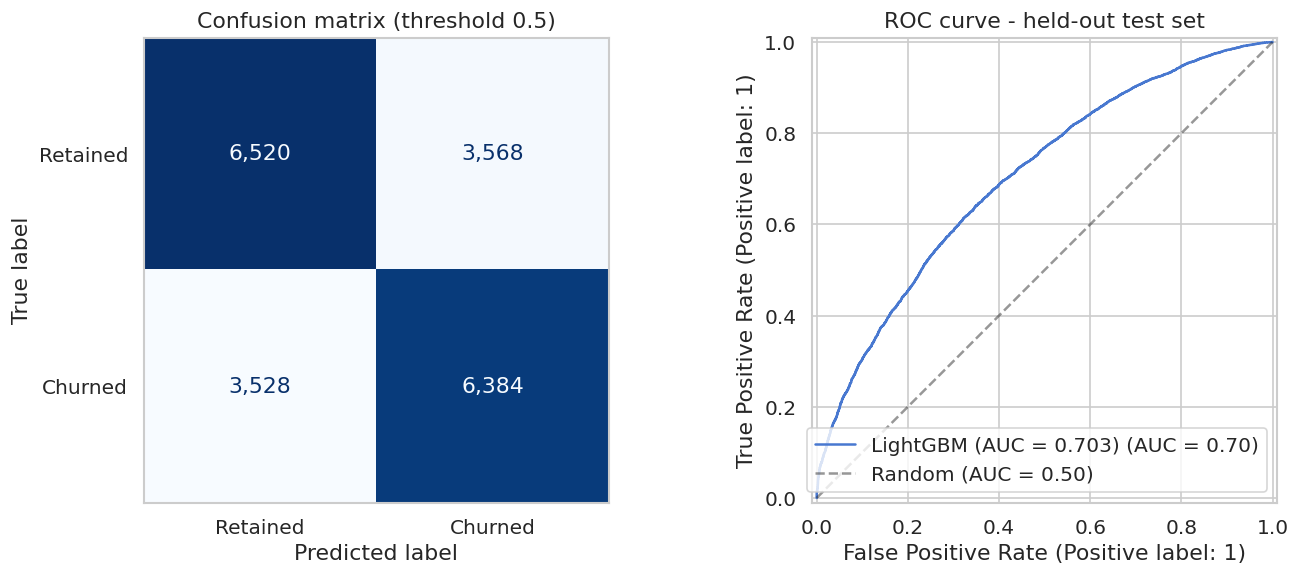

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(yt, y_pred_test), display_labels=["Retained", "Churned"]).plot(
    ax=axes[0], colorbar=False, cmap="Blues", values_format=","
)
axes[0].set_title("Confusion matrix (threshold 0.5)")
axes[0].grid(False)
RocCurveDisplay.from_predictions(yt, y_proba_test, ax=axes[1], name=f"LightGBM (AUC = {m['auc']:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", alpha=0.45, label="Random (AUC = 0.50)")
axes[1].set_title("ROC curve - held-out test set")
axes[1].legend(loc="lower right")
plt.tight_layout()
plotting.save_fig(fig, "test_confusion_roc")
plt.show()

The two errors cost different amounts:

- **False negatives** (churners missed, bottom-left) cost their future revenue.
- **False positives** (loyal customers flagged, top-right) cost an unnecessary offer.

How many to contact therefore depends on offer cost, retention success and the *real* churn rate, all of which Section 9 works through.

---
## 8. SHAP Interpretation

SHAP values (Lundberg & Lee, 2017) show which features drive each prediction and in which direction. They are computed on 2,000 random test customers and averaged over the five seed models, which is exact because the ensemble averages log-odds. Each dot is one customer: its position is the push towards (right) or away from (left) churn, and its colour is the feature value (red = high).

Top 10 features by mean |SHAP|:
eqpdays               0.1765
months                0.1593
mou_change_pct        0.1589
recent_vs_life_mou    0.1256
hnd_price             0.0866
totmrc_Mean           0.0837
uniqsubs              0.0834
crclscod              0.0681
lor                   0.0640
drop_vce_Mean         0.0632


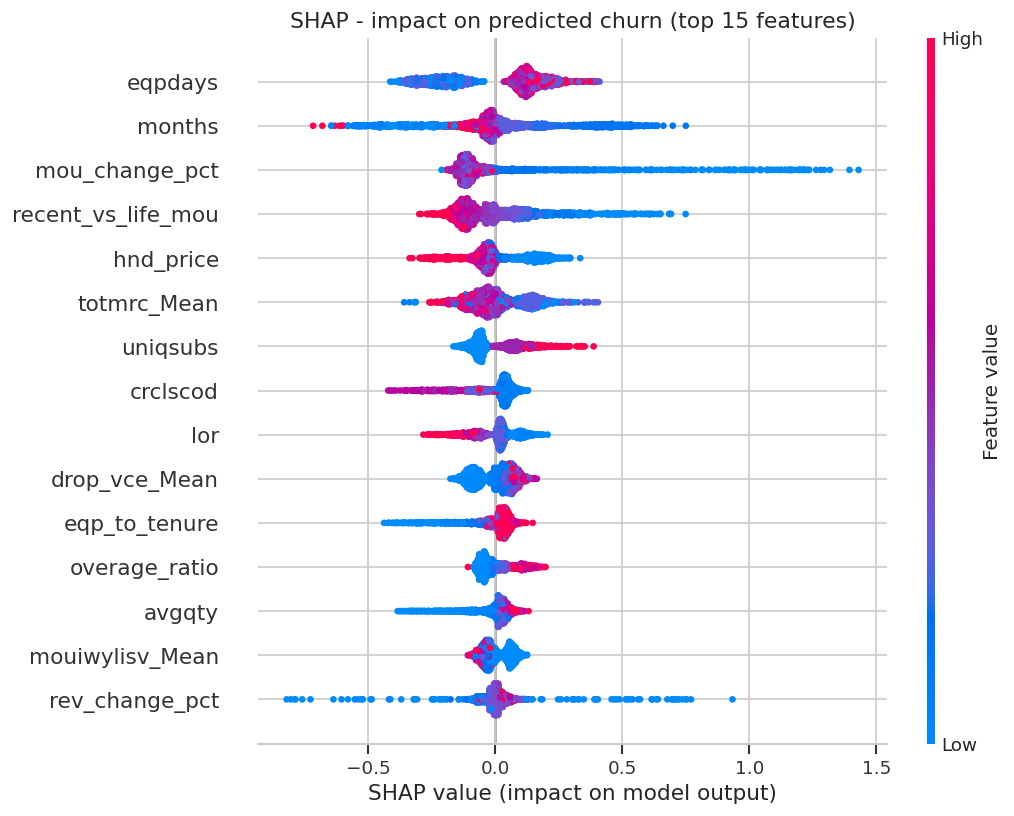

In [16]:
X_shap = X_test_t.iloc[np.random.default_rng(SEED).choice(len(X_test_t), size=2000, replace=False)]
sv = ev.ensemble_shap(final_model, X_shap)

shap_rank = pd.Series(np.abs(sv).mean(axis=0), index=X_shap.columns).sort_values(ascending=False)
print("Top 10 features by mean |SHAP|:")
print(shap_rank.head(10).round(4).to_string())

shap.summary_plot(sv, X_shap, max_display=15, show=False, plot_size=(9, 7))
plt.title("SHAP - impact on predicted churn (top 15 features)")
plt.tight_layout()
plotting.save_fig(plt.gcf(), "shap_beeswarm")
plt.show()

| Rank | Feature | Direction | Actionable? |
|---|---|---|---|
| 1 | `eqpdays` (handset age) | older handsets churn more | Yes: upgrade offer |
| 2 | `months` (tenure) | non-linear, peak around 11-15 months | Yes: pre-renewal outreach |
| 3-4 | `mou_change_pct`, `recent_vs_life_mou` (engineered) | falling usage relative to own history raises churn | Yes: usage check-in |
| 5+ | `hnd_price`, `totmrc_Mean`, `uniqsubs`, `crclscod` and others | mixed | Partly, or informative only |

The model's drivers match the EDA. The two engineered usage ratios outrank every raw usage column, which confirms that usage *relative to the customer's own history* carries more signal than absolute usage.

---
## 9. Business Impact

A model score becomes a proposal only once it says who to target, at what cost and for what return. Each contacted customer receives the offer matching their main driver: a handset upgrade, a pre-renewal loyalty offer or a usage check-in. The business case is built in four steps:

| Step | Question |
|---|---|
| 9.1 | What does a top-10% campaign return on the sample as provided? |
| 9.2 | What changes at a realistic churn rate? |
| 9.3 | Who should be contacted: highest risk, or highest expected value? |
| 9.4 | How should the pilot be designed? |

All assumptions live in one `Assumptions` object (`churn/config.py`) and can be replaced with Telecom's figures.

### 9.1 As sampled: top-decile campaign

Assumptions(monthly_revenue=48.195, lifetime_months=24, success_rate=0.3, offer_cost_months=1.0, true_churn_rate=0.03, customer_base=100000) 

        precision  churners  customers   lift  cum_recall
decile                                                   
1           0.814      1629       2000  1.643       0.164
2           0.686      1371       2000  1.383       0.303
3           0.604      1208       2000  1.219       0.425
4           0.586      1172       2000  1.182       0.543
5           0.515      1030       2000  1.039       0.647
6           0.453       906       2000  0.914       0.738
7           0.437       874       2000  0.882       0.826
8           0.378       755       2000  0.762       0.902
9           0.299       598       2000  0.603       0.963
10          0.184       369       2000  0.372       1.000


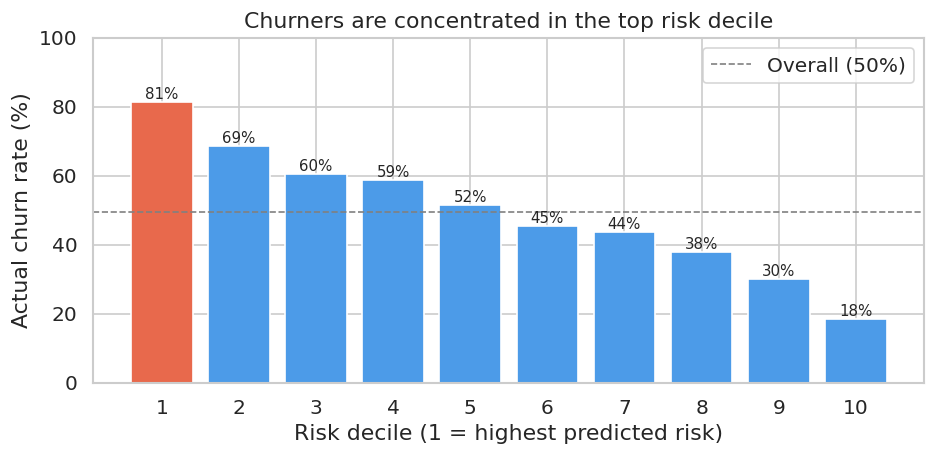

In [17]:
A = Assumptions(monthly_revenue=float(df["rev_Mean"].median()))
print(A, "\n")

gains = ev.gains_table(yt, y_proba_test)
print(gains.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
plotting.rate_bars(
    ax,
    gains["precision"],
    yt.mean(),
    colors=[CHURN_C] + [STAY_C] * 9,
    ylim=100,
    bold=False,
    fontsize=9,
    title="Churners are concentrated in the top risk decile",
    xlabel="Risk decile (1 = highest predicted risk)",
    ylabel="Actual churn rate (%)",
)
ax.legend()
plt.tight_layout()
plotting.save_fig(fig, "gains_by_decile")
plt.show()

In [18]:
top_precision = gains.loc[1, "precision"]
sampled = pd.DataFrame(
    {
        f"Top 10%, {s:.0%} success": business.sample_campaign(A, top_precision, share=0.10, success_rate=s)
        for s in [0.10, 0.20, 0.30, 0.40]
    }
).T
sampled.loc["Everyone >= 0.5, 30% success"] = business.sample_campaign(
    A, m["precision"], share=(y_proba_test >= 0.5).mean()
)
print(f"Per {A.customer_base:,} customers, 24 months, at the sample's 50% churn rate:\n")
print(business.fmt_campaign(sampled).to_string())

Per 100,000 customers, 24 months, at the sample's 50% churn rate:

                             contacted churners reached retained revenue saved  offer cost         net   ROI
Top 10%, 10% success            10,000            8,145      814      $942,116    $481,950    $460,166  1.0x
Top 10%, 20% success            10,000            8,145    1,629    $1,884,232    $481,950  $1,402,282  2.9x
Top 10%, 30% success            10,000            8,145    2,444    $2,826,348    $481,950  $2,344,398  4.9x
Top 10%, 40% success            10,000            8,145    3,258    $3,768,463    $481,950  $3,286,513  6.8x
Everyone >= 0.5, 30% success    49,760           31,920    9,576   $11,076,368  $2,398,183  $8,678,184  3.6x


On the sample, the top decile is right about 4 times in 5, and a top-10% campaign returns several times its cost (+\$2.3M at 30% success). The catch is the base rate. These figures take the sample's 50% churn rate at face value.

### 9.2 Correcting for the real churn rate

Because the model was trained on a 50/50 sample:

- **Its probabilities are on the sample's scale.** A score of 0.8 means "80% chance of churn *if churn were as common as in this sample*".
- **Precision measured on the sample is inflated.** With 50% churners, even a mediocre ranking finds churners easily.

The *ranking* is unaffected, provided the sample was drawn at random within each class. AUC and the share of churners and stayers caught at any cut-off carry over; only the mix changes. The standard prior-shift correction (Saerens et al., 2002) adjusts for that:

$$p_{\text{real}} = \frac{p \cdot \pi / \pi_s}{p \cdot \pi / \pi_s + (1-p)(1-\pi)/(1-\pi_s)}$$

Here $\pi_s$ = 49.6% is the sample rate and $\pi$ is the real rate. To evaluate campaigns on the test set as if it were the real base, each churner is weighted by $\pi/\pi_s$ and each stayer by $(1-\pi)/(1-\pi_s)$.

**Assumed real rate: $\pi$ = 3% per month.** Annual churn of 20-40% corresponds to roughly 2-4% per month, and the target window is one month long. Telecom's own figure should replace this. The sensitivity analysis below covers 2-5%.

The correction also requires the probabilities to be calibrated *on the sample's scale*, which the reliability check (Niculescu-Mizil & Caruana, 2005) confirms.

Brier score 0.2181; max decile gap between predicted and observed churn 0.023


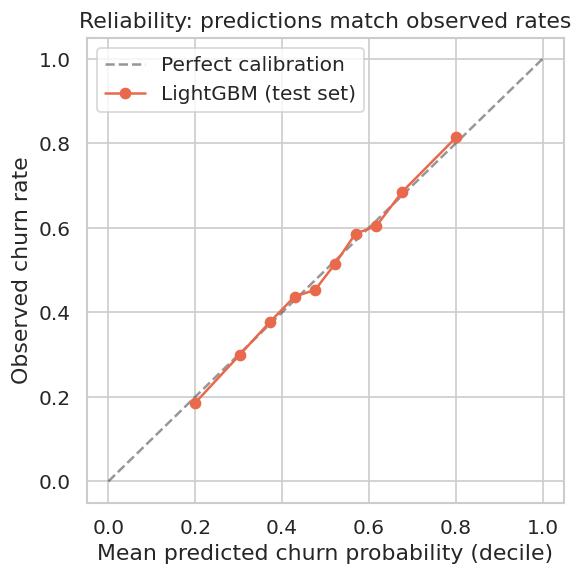


Riskiest 10% who really churn:  as sampled 81.5%  |  at 3% real churn 8.9% (lift 3.0x)


In [19]:
frac_pos, mean_pred = calibration_curve(yt, y_proba_test, n_bins=10, strategy="quantile")
print(
    f"Brier score {brier_score_loss(yt, y_proba_test):.4f}; "
    f"max decile gap between predicted and observed churn {np.max(np.abs(frac_pos - mean_pred)):.3f}"
)

fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 1], [0, 1], "k--", alpha=0.45, label="Perfect calibration")
ax.plot(mean_pred, frac_pos, "o-", color=CHURN_C, label="LightGBM (test set)")
ax.set_xlabel("Mean predicted churn probability (decile)")
ax.set_ylabel("Observed churn rate")
ax.set_title("Reliability: predictions match observed rates")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

SAMPLE_RATE = y_tv.mean()
w_real = business.real_weights(yt, A.true_churn_rate, SAMPLE_RATE)
prec_real = business.weighted_top_share_precision(y_proba_test, yt, w_real, share=0.10)
print(
    f"\nRiskiest 10% who really churn:  as sampled {m['top10']:.1%}  |  "
    f"at {A.true_churn_rate:.0%} real churn {prec_real:.1%} (lift {prec_real / A.true_churn_rate:.1f}x)"
)

At a realistic churn rate the model still concentrates churners, since the riskiest 10% churn at 3x the average rate. In absolute terms, though, most of them will not churn. The 81.5% precision behind Section 9.1 does not hold on the real base.

### 9.3 Who to contact: risk vs expected value

Following cost-sensitive decision theory (Elkan, 2001) and profit-based churn evaluation (Verbeke et al., 2012), the expected 24-month value of contacting customer *i* is

$$EV_i = \underbrace{p_{\text{real},i} \times s \times L \times r_i}_{\text{revenue saved if they stay}} \; - \; \underbrace{c \times r_i}_{\text{offer cost}}$$

with retention success $s$ = 30%, horizon $L$ = 24 months, the customer's own monthly revenue $r_i$, and offer cost $c$ = 1 month of revenue. Three policies are compared on the reweighted test set, scaled to 100,000 customers:

| Policy | Rule |
|---|---|
| A | Top 10% by churn probability (the Section 9.1 plan) |
| B | Top 10% by expected value: same number of contacts, ranked by risk x revenue |
| C | Everyone with EV > 0. Because offer cost is proportional to revenue, this means $p_{\text{real}} > c/(s \cdot L)$ = 13.9% |

Revenue is capped at the 99th percentile. Revenue saved uses the test customers' *actual* outcomes, not the model's predictions.

In [20]:
rev_test = X_test["rev_Mean"].fillna(X_tv["rev_Mean"].median()).clip(0, X_tv["rev_Mean"].quantile(0.99))
sim = business.CampaignSimulator(y_proba_test, yt, rev_test, A, SAMPLE_RATE)

print(f"Break-even churn probability: {A.breakeven_probability:.1%}\n")
print(f"Per 100,000 customers, real churn {A.true_churn_rate:.0%}/month, 24 months:")
print(business.fmt_campaign(sim.compare()).to_string())

by_rate = pd.DataFrame(
    {
        (f"{r:.0%}" if r < 0.4 else f"{r:.0%} (as sampled)"): sim.compare(true_rate=r)["net"]
        for r in [0.02, 0.03, 0.05, SAMPLE_RATE]
    }
)
print("\nNet impact by assumed real monthly churn rate:")
print(by_rate.map(business.money).to_string())

by_cost = {}
for c in [1.0, 0.5, 0.25]:
    t = sim.compare(offer_cost_months=c)
    by_cost[f"{c:g} month(s), break-even p = {c / (A.success_rate * A.lifetime_months):.1%}"] = {
        "A: net": business.money(t.loc["A. Top 10% by churn probability", "net"]),
        "C: net": business.money(t.loc["C. Everyone with EV > 0", "net"]),
        "C: contacted": f"{t.loc['C. Everyone with EV > 0', 'contacted']:,.0f}",
    }
by_cost = pd.DataFrame(by_cost).T
print(f"\nNet impact by offer cost (real churn {A.true_churn_rate:.0%}/month):")
print(by_cost.to_string())

Break-even churn probability: 13.9%

Per 100,000 customers, real churn 3%/month, 24 months:
                                contacted churners reached precision revenue saved offer cost        net    ROI
A. Top 10% by churn probability     9,991              886      8.9%      $341,220   $554,880  -$213,660  -0.4x
B. Top 10% by expected value        9,998              604      6.0%      $127,136   $199,021   -$71,885  -0.4x
C. Everyone with EV > 0               721              173     24.0%       $52,817    $29,950    $22,867   0.8x

Net impact by assumed real monthly churn rate:
                                        2%         3%       5% 50% (as sampled)
A. Top 10% by churn probability  -$326,160  -$213,660   $2,325       $2,404,660
B. Top 10% by expected value     -$109,487   -$71,885  $33,687       $4,319,493
C. Everyone with EV > 0             $3,038    $22,867  $70,979      $14,600,769



Net impact by offer cost (real churn 3%/month):
                                       A: net    C: net C: contacted
1 month(s), break-even p = 13.9%    -$213,660   $22,867          721
0.5 month(s), break-even p = 6.9%     $63,780   $72,231        4,936
0.25 month(s), break-even p = 3.5%   $202,500  $268,378       29,201


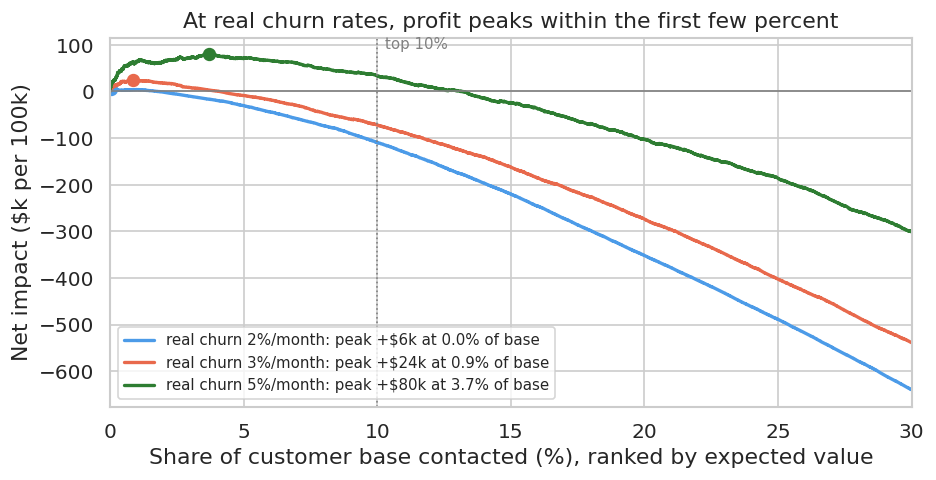

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for r, col in [(0.02, STAY_C), (0.03, CHURN_C), (0.05, GREEN_C)]:
    x, cum = sim.profit_curve(r)
    cum = cum / 1e3
    i, keep = np.argmax(cum), x <= 30
    ax.plot(
        x[keep],
        cum[keep],
        color=col,
        lw=2,
        label=f"real churn {r:.0%}/month: peak +${cum[i]:,.0f}k at {x[i]:.1f}% of base",
    )
    ax.plot(x[i], cum[i], "o", color=col, ms=7)
ax.axhline(0, color="grey", lw=1)
ax.axvline(10, color="grey", ls=":", lw=1)
ax.text(10.3, ax.get_ylim()[1] * 0.8, "top 10%", color="grey", fontsize=9)
ax.set_xlim(0, 30)
ax.set_xlabel("Share of customer base contacted (%), ranked by expected value")
ax.set_ylabel("Net impact ($k per 100k)")
ax.set_title("At real churn rates, profit peaks within the first few percent")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout()
plotting.save_fig(fig, "profit_curve")
plt.show()

**What this shows**

1. **At a realistic churn rate, a fixed top-10% campaign loses money.** Only 8.9% of the top decile really churn. That is 3x the average, but below the 13.9% break-even, so policy A goes from +\$2.4M as sampled to about -\$0.2M per 100k customers.
2. **The profitable campaign is small and sharply targeted.** Policy C contacts only ~0.7% of the base, at 24% precision, for about +\$23k per 100k. For every plausible churn rate, profit peaks within the first few percent of the base.
3. **Revenue weighting helps only when the contacts are worth making.** On the sample's scale, ranking by expected value lifts net impact by about 80% for the same 10,000 contacts (\$4.3M vs \$2.4M). At the real rate almost no one in the top 10% clears break-even, so a fixed quota is the wrong design whatever the ranking. Policy C is already revenue-aware.
4. **Offer cost is the biggest lever.** At half a month's revenue, about 5% of the base is worth contacting. At a quarter (for example a call, with the offer only for those who respond), about 29% is, for roughly +\$270k per 100k. The economics depend far more on intervention cost and success rate than on another 0.01 of AUC.

The proposal therefore becomes: score monthly, contact customers with positive expected value, and use the pilot to measure the numbers that set how many that is: the real retention success rate and cost per save.

### 9.4 Pilot design: from churn risk to uplift

Every policy above targets customers likely to leave. The customers worth contacting, though, are those whose decision an offer can change. That difference is *uplift*, and it cannot be estimated from this data because nobody in it received an offer. The pilot is designed to produce it:

1. **Randomise.** Split eligible customers into treatment (receives the matched offer) and control (receives nothing). The control arm turns "churn among contacted customers" into a causal retention rate.
2. **Include some customers below the cut-off** in both arms, so the uplift model can learn how offer response varies with risk.
3. **Record** the offer type, the contact date and churn at 60 days.
4. **Model uplift** with a T-learner (Künzel et al., 2019; separate churn models for treated and control customers, uplift = $p_{control} - p_{treated}$). Evaluate it with a Qini curve (Radcliffe, 2007), then target by uplift x revenue.

In [22]:
p_control = sim.compare().loc["C. Everyone with EV > 0", "precision"]
n_arm = business.pilot_size(p_control, relative_reduction=A.success_rate)
print(f"Expected churn - control {p_control:.1%} vs treated {p_control * (1 - A.success_rate):.1%}")
print(f"Customers needed per arm (80% power, 5% significance): {n_arm:,}   (total {2 * n_arm:,})")

Expected churn - control 24.0% vs treated 16.8%
Customers needed per arm (80% power, 5% significance): 487   (total 974)


About 490 customers per arm are enough to detect a 30% relative reduction in churn (from 24% to 17%). Policy C selects ~720 customers a month per 100k, so the pilot needs about 6-8 weeks of monthly scoring, or a slightly lower cut-off.

---
## 10. Conclusion

| Item | Result |
|---|---|
| Final model | LightGBM, Optuna-tuned, 5-seed average (102 features) |
| Test AUC-ROC | 0.703 (95% CI 0.696-0.709) |
| Test F1 / precision / recall (0.5 threshold) | 0.643 / 0.642 / 0.644 |
| Top-decile precision | 81.5% as sampled, 8.9% at 3% real churn (3.0x average) |
| Top-10% campaign, net per 100k (24 months) | +\$2.4M as sampled, -\$0.2M at 3% real churn |
| Expected-value campaign (p > 13.9%) | ~0.7% of base, +\$23k per 100k; +\$270k if the offer costs a quarter of a month's revenue |
| Pilot size | ~490 customers per arm |

**Key findings**

1. **Handset age** is the strongest driver. Churn rises from 40% to 58% as handsets age, and it is the top SHAP feature.
2. **Tenure** matters non-linearly. Churn nearly doubles at the one-year mark, consistent with contract expiry.
3. **Disengaged customers leave quietly.** Falling usage raises risk, while churners call customer care *less*, so waiting for complaints misses them.
4. **No single variable separates churners from stayers.** A tuned gradient-boosting model combining ~100 weak signals reaches a test AUC of 0.703, against 0.642 for a well-specified linear model.
5. **The model ranks well, but at real churn rates most flagged customers stay.** The business case depends on offer cost and retention success far more than on model accuracy.

**Recommendation.** Score the base monthly and contact customers whose offer has positive expected value, matching each to an upgrade offer, a pre-renewal loyalty offer or a usage check-in. Run a randomised pilot (~490 per arm) to measure the real retention rate and cost per save. Re-set the contact threshold from those figures, and use the pilot data to move from churn-risk to uplift targeting.

---
## References


**Market context**

- Gallo, A. (2014). The value of keeping the right customers. *Harvard Business Review*. https://hbr.org/2014/10/the-value-of-keeping-the-right-customers
- ITU (2024). *Facts and Figures 2024: Mobile-cellular subscriptions*. https://www.itu.int/itu-d/reports/statistics/2024/11/10/ff24-subscriptions/
- Nguyen, N. Y., Tran, V. L., & Dao, V. T. S. (2022). Churn prediction in telecommunication industry using kernel Support Vector Machines. *PLOS ONE*, 17(5). https://doi.org/10.1371/journal.pone.0267935

**Data**

- Neslin, S. A., Gupta, S., Kamakura, W., Lu, J., & Mason, C. H. (2006). Defection detection: Measuring and understanding the predictive accuracy of customer churn models. *Journal of Marketing Research*, 43(2), 204-211. https://doi.org/10.1509/jmkr.43.2.204 (The course dataset is anonymised as "Company A". Its column names appear to match the Teradata Center / Duke University churn-tournament data described in this paper.)

**Modelling and evaluation**

- Ke, G. et al. (2017). LightGBM: A highly efficient gradient boosting decision tree. *NeurIPS*. https://lightgbm.readthedocs.io/
- Akiba, T., Sano, S., Yanase, T., Ohta, T., & Koyama, M. (2019). Optuna: A next-generation hyperparameter optimization framework. *KDD*. https://doi.org/10.1145/3292500.3330701
- Bergstra, J., Bardenet, R., Bengio, Y., & Kegl, B. (2011). Algorithms for hyper-parameter optimization. *NeurIPS*.
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS*. https://shap.readthedocs.io/
- Niculescu-Mizil, A., & Caruana, R. (2005). Predicting good probabilities with supervised learning. *ICML*. https://doi.org/10.1145/1102351.1102430
- Efron, B., & Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825-2830. https://jmlr.org/papers/v12/pedregosa11a.html

**Business case and campaign design**

- Saerens, M., Latinne, P., & Decaestecker, C. (2002). Adjusting the outputs of a classifier to new a priori probabilities: A simple procedure. *Neural Computation*, 14(1), 21-41. https://doi.org/10.1162/089976602753284446
- Elkan, C. (2001). The foundations of cost-sensitive learning. *Proceedings of IJCAI 2001*.
- Verbeke, W., Dejaeger, K., Martens, D., Hur, J., & Baesens, B. (2012). New insights into churn prediction in the telecommunication sector: A profit driven data mining approach. *European Journal of Operational Research*, 218(1), 211-229. https://www.sciencedirect.com/science/article/abs/pii/S0377221711008599
- Künzel, S. R., Sekhon, J. S., Bickel, P. J., & Yu, B. (2019). Metalearners for estimating heterogeneous treatment effects using machine learning. *PNAS*, 116(10), 4156-4165. https://doi.org/10.1073/pnas.1804597116
- Radcliffe, N. J. (2007). Using control groups to target on predicted lift: Building and assessing uplift models. *Direct Marketing Analytics Journal*, 1, 14-21.